# Criptografia pós-quântica na prática: tamanhos, handshake e a ideia do LWE

**Palestra:** *Uma década quântica na nuvem e a contagem regressiva da criptografia* · IBM Qiskit Fall Fest Brasil 2026 (slides 9, 10 e 11)
**Autor:** Jullyano Lino

> **Leia antes de rodar:** este notebook **não usa computador quântico**. A criptografia pós-quântica (PQC) roda em computadores **clássicos**; ela é "pós-quântica" porque resiste (até onde se sabe) ao algoritmo de Shor. O que fazemos aqui: (1) **derivar dos parâmetros dos padrões** os tamanhos de chaves, cifrados e assinaturas e conferi-los com as tabelas publicadas; (2) montar um **modelo transparente** do custo em bytes de um *handshake* TLS 1.3; (3) rodar um **LWE de brinquedo** para entender a ideia (**inseguro de propósito**: parâmetros minúsculos, sem proteções).

## O que você vai fazer
1. **Verificar** os tamanhos de ML-KEM (FIPS 203), ML-DSA (FIPS 204) e SLH-DSA (FIPS 205) por fórmulas, com `assert` contra as tabelas publicadas.
2. Comparar com os clássicos (X25519, ECDSA P-256, RSA-2048) e ver o **fator de aumento**.
3. Contar bytes de um *handshake* em cenários (hoje, híbrido, PQC completo), com as suposições **explícitas**.
4. Cifrar e decifrar um bit com **LWE**, ver por que o **ruído** é essencial e como a decifração falha se o ruído passar do limite.
5. Treinar com exercícios (gabaritos no fim).

**Não precisa de conta IBM, token ou hardware.** Tempo total: segundos.

## Sumário
1. Configuração · 2. Tamanhos derivados dos padrões · 3. Clássico × pós-quântico · 4. Modelo de handshake · 5. LWE de brinquedo · 6. Exercícios · 7. Gabaritos · 8. Fontes

In [1]:
import math, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.width", 140)

## 2. Tamanhos derivados dos padrões

Em agosto de 2024 o NIST publicou os três primeiros padrões FIPS de PQC: **FIPS 203** (ML-KEM, troca de chaves/encapsulamento, derivado do CRYSTALS-Kyber), **FIPS 204** (ML-DSA, assinatura, derivado do CRYSTALS-Dilithium) e **FIPS 205** (SLH-DSA, assinatura baseada em hash, derivado do SPHINCS+) [F1][F2][F3].

Em vez de copiar tabelas, **calculamos** os tamanhos a partir dos parâmetros e conferimos com as constantes publicadas (aqui transcritas das tabelas de implementação de referência do Open Quantum Safe/liboqs [F4], conferidas nesta produção). Se a fórmula e a tabela divergirem, o `assert` falha: isso protege contra erro de digitação em qualquer um dos lados.

**Fórmulas** (tamanhos em bytes; $q=3329$ no ML-KEM; $q=8380417$ e $d=13$ no ML-DSA):

| Esquema | Chave pública | Chave secreta | Cifrado/assinatura |
|---|---|---|---|
| ML-KEM (parâmetros $k,d_u,d_v$) | $384k+32$ | $768k+96$ | $32(d_u k+d_v)$ |
| ML-DSA ($k,\ell,\eta,\gamma_1=2^{g},\omega,\lambda$) | $32+320k$ | $128+32\big((k+\ell)\,\mathrm{bl}(2\eta)+dk\big)$ | $\lambda/4+32\,\ell\,(1+g)+\omega+k$ |
| SLH-DSA ($n,h,d,a,k$; $w=16$) | $2n$ | $4n$ | $(1+k(a+1)+h+d\cdot\mathrm{len})\,n$ |

com $\mathrm{bl}(x)$ = número de bits de $x$, e $\mathrm{len}=\mathrm{len}_1+\mathrm{len}_2$, $\mathrm{len}_1=\lceil 8n/\log_2 w\rceil$, $\mathrm{len}_2=\lfloor \log_2(\mathrm{len}_1(w-1))/\log_2 w\rfloor+1$.

> Tamanhos **brutos** do padrão. Em certificados X.509 e em protocolos, há codificação e metadados adicionais (dezenas de bytes).

In [2]:
# ---------------- Constantes PUBLICADAS (liboqs/OQS [F4]) para conferência ----------------
PUBLISHED = {
    # nome: (nível NIST, chave pública, chave secreta, cifrado ou assinatura)
    "ML-KEM-512":   (1,  800, 1632,  768),
    "ML-KEM-768":   (3, 1184, 2400, 1088),
    "ML-KEM-1024":  (5, 1568, 3168, 1568),
    "ML-DSA-44":    (2, 1312, 2560, 2420),
    "ML-DSA-65":    (3, 1952, 4032, 3309),
    "ML-DSA-87":    (5, 2592, 4896, 4627),
    "SLH-DSA-128s": (1,   32,   64,  7856),
    "SLH-DSA-128f": (1,   32,   64, 17088),
    "SLH-DSA-192s": (3,   48,   96, 16224),
    "SLH-DSA-192f": (3,   48,   96, 35664),
    "SLH-DSA-256s": (5,   64,  128, 29792),
    "SLH-DSA-256f": (5,   64,  128, 49856),
}

# ---------------- Parâmetros dos padrões e fórmulas ----------------
KEM_PARAMS = {"ML-KEM-512": (2, 10, 4), "ML-KEM-768": (3, 10, 4), "ML-KEM-1024": (4, 11, 5)}          # (k, du, dv)
DSA_PARAMS = {"ML-DSA-44": (4, 4, 2, 17, 80, 128), "ML-DSA-65": (6, 5, 4, 19, 55, 192),                # (k, l, eta, g, omega, lambda)
              "ML-DSA-87": (8, 7, 2, 19, 75, 256)}
SLH_PARAMS = {"SLH-DSA-128s": (16, 63, 7, 12, 14), "SLH-DSA-128f": (16, 66, 22, 6, 33),                # (n, h, d, a, k)
              "SLH-DSA-192s": (24, 63, 7, 14, 17), "SLH-DSA-192f": (24, 66, 22, 8, 33),
              "SLH-DSA-256s": (32, 64, 8, 14, 22), "SLH-DSA-256f": (32, 68, 17, 9, 35)}

def bitlen(x): return int(x).bit_length()

def mlkem_sizes(k, du, dv):
    return 384*k + 32, 768*k + 96, 32*(du*k + dv)

def mldsa_sizes(k, l, eta, g, omega, lam, d=13):
    pk = 32 + 320*k                                           # 32 + 32*k*(bl(q-1) - d), com bl(q-1)=23 e d=13
    sk = 128 + 32*((k + l)*bitlen(2*eta) + d*k)
    sig = lam//4 + 32*l*(1 + g) + omega + k
    return pk, sk, sig

def slhdsa_sizes(n, h, d, a, k, w=16):
    len1 = math.ceil(8*n / math.log2(w))
    len2 = math.floor(math.log2(len1*(w - 1)) / math.log2(w)) + 1
    sig = (1 + k*(a + 1) + h + d*(len1 + len2)) * n
    return 2*n, 4*n, sig

DERIVED = {}
for name, prm in KEM_PARAMS.items(): DERIVED[name] = mlkem_sizes(*prm)
for name, prm in DSA_PARAMS.items(): DERIVED[name] = mldsa_sizes(*prm)
for name, prm in SLH_PARAMS.items(): DERIVED[name] = slhdsa_sizes(*prm)

rows = []
for name, (lvl, pk, sk, ct) in PUBLISHED.items():
    assert DERIVED[name] == (pk, sk, ct), (name, DERIVED[name], (pk, sk, ct))
    rows.append(dict(esquema=name, nivel_NIST=lvl, chave_publica=pk, chave_secreta=sk,
                     **{"cifrado_ou_assinatura": ct}))
df_pq = pd.DataFrame(rows)
print("Fórmulas dos padrões == tabelas publicadas: OK para", len(rows), "conjuntos de parâmetros")
df_pq

Fórmulas dos padrões == tabelas publicadas: OK para 12 conjuntos de parâmetros


,esquema,nivel_NIST,chave_publica,chave_secreta,cifrado_ou_assinatura
0,ML-KEM-512,1,800,1632,768
1,ML-KEM-768,3,1184,2400,1088
2,ML-KEM-1024,5,1568,3168,1568
3,ML-DSA-44,2,1312,2560,2420
4,ML-DSA-65,3,1952,4032,3309
5,ML-DSA-87,5,2592,4896,4627
6,SLH-DSA-128s,1,32,64,7856
7,SLH-DSA-128f,1,32,64,17088
8,SLH-DSA-192s,3,48,96,16224
9,SLH-DSA-192f,3,48,96,35664


## 3. Clássico × pós-quântico: quanto cresce?

Referências clássicas (bytes), **mesmas convenções que usaremos no handshake**:
- **X25519**: compartilhamento de chave de 32 B em cada direção [F5].
- **ECDSA P-256**: chave pública em `SubjectPublicKeyInfo` DER = 91 B; assinatura DER de até ~72 B (64 B "crus") [F6].
- **RSA-2048**: chave pública em DER ≈ 294 B; assinatura = 256 B.

> Esses números clássicos são **valores típicos de codificação**, citados como ordem de grandeza; para comparar com PQC o que importa é a razão (dezenas de vezes), não o byte exato.

,chave pública (B),assinatura (B),assinatura × ECDSA
ECDSA P-256,91,72,1.0
ML-DSA-44,1312,2420,33.6
ML-DSA-65,1952,3309,46.0
SLH-DSA-128s,32,7856,109.1


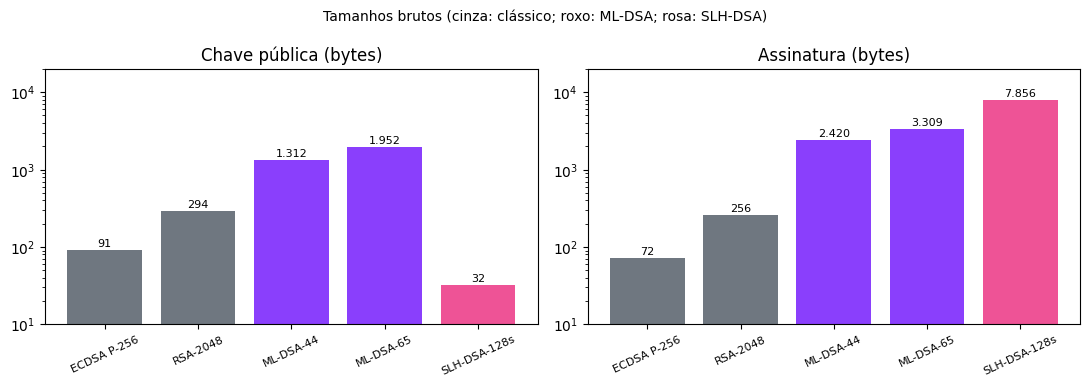

In [3]:
CLASSICAL = {                      # (chave pública, assinatura ou compartilhamento)
    "X25519 (share)":      (32, 32),
    "ECDSA P-256 (DER)":   (91, 72),
    "RSA-2048 (DER)":      (294, 256),
}
tbl = pd.DataFrame({
    "chave pública (B)": [CLASSICAL["ECDSA P-256 (DER)"][0], PUBLISHED["ML-DSA-44"][1], PUBLISHED["ML-DSA-65"][1], PUBLISHED["SLH-DSA-128s"][1]],
    "assinatura (B)":    [CLASSICAL["ECDSA P-256 (DER)"][1], PUBLISHED["ML-DSA-44"][3], PUBLISHED["ML-DSA-65"][3], PUBLISHED["SLH-DSA-128s"][3]],
}, index=["ECDSA P-256", "ML-DSA-44", "ML-DSA-65", "SLH-DSA-128s"])
tbl["assinatura × ECDSA"] = (tbl["assinatura (B)"] / tbl.loc["ECDSA P-256", "assinatura (B)"]).round(1)
display(tbl)

# Gráfico (log) para o slide: assinaturas e chaves públicas
fig, axes = plt.subplots(1, 2, figsize=(11, 3.9))
names = ["ECDSA P-256", "RSA-2048", "ML-DSA-44", "ML-DSA-65", "SLH-DSA-128s"]
pk = [91, 294, 1312, 1952, 32]; sg = [72, 256, 2420, 3309, 7856]
for ax, vals, title in ((axes[0], pk, "Chave pública (bytes)"), (axes[1], sg, "Assinatura (bytes)")):
    bars = ax.bar(names, vals, color=["#6f7780", "#6f7780", "#8a3ffc", "#8a3ffc", "#ee5396"]); ax.set_yscale("log"); ax.set_title(title)
    for b_, v in zip(bars, vals): ax.text(b_.get_x() + b_.get_width()/2, v*1.1, f"{v:,}".replace(",", "."), ha="center", fontsize=8)
    ax.tick_params(axis="x", rotation=25, labelsize=8); ax.set_ylim(10, 2e4)
fig.suptitle("Tamanhos brutos (cinza: clássico; roxo: ML-DSA; rosa: SLH-DSA)", fontsize=10); fig.tight_layout(); plt.show()

## 4. Modelo de *handshake*: quantos bytes de chave e assinatura?

### 4.1 Compartilhamentos de chave
No TLS 1.3, o cliente envia um compartilhamento de chave e o servidor responde com o seu. Com **X25519MLKEM768** (híbrido), o compartilhamento do cliente concatena a chave de encapsulamento ML-KEM-768 (1184 B) com a chave X25519 (32 B) = **1216 B**; o do servidor concatena o cifrado ML-KEM-768 (1088 B) com a chave X25519 (32 B) = **1120 B**. A ordem (ML-KEM primeiro, X25519 depois) segue o rascunho IETF [F7]. É um **rascunho**: confira a versão vigente antes de citar.

### 4.2 O modelo (leia as suposições!)
Contamos **apenas** bytes de **compartilhamentos de chave + chaves públicas + assinaturas**:

- Cadeia de certificados enviada pelo servidor com `n` certificados (a raiz não é enviada). Cada certificado carrega 1 chave pública e 1 assinatura do emissor.
- Mais 1 assinatura do `CertificateVerify` (feita com a chave do certificado folha).
- Logo: `assinaturas = n + 1` e `chaves públicas = n`.
- **Ignorados:** cabeçalhos TLS, extensões, nomes/validade/campos X.509, SCT, grampeamento OCSP, ECH, resumos. Na prática o handshake é **maior** que o modelo; o modelo serve para **comparar cenários**, não para prever bytes na rede.
- Hipótese simplificadora: mesma família de assinatura em todos os certificados.

In [4]:
KEX = {  # nome: (share do cliente, share do servidor)  -- bytes
    "X25519":           (32, 32),
    "X25519MLKEM768":   (PUBLISHED["ML-KEM-768"][1] + 32, PUBLISHED["ML-KEM-768"][3] + 32),   # 1216, 1120 [F7]
    "MLKEM768":         (PUBLISHED["ML-KEM-768"][1],      PUBLISHED["ML-KEM-768"][3]),         # 1184, 1088
}
assert KEX["X25519MLKEM768"] == (1216, 1120)

SIG = {  # nome: (chave pública, assinatura) -- bytes
    "ECDSA-P256": CLASSICAL["ECDSA P-256 (DER)"],
    "RSA-2048":   CLASSICAL["RSA-2048 (DER)"],
    "ML-DSA-44":  (PUBLISHED["ML-DSA-44"][1], PUBLISHED["ML-DSA-44"][3]),
    "ML-DSA-65":  (PUBLISHED["ML-DSA-65"][1], PUBLISHED["ML-DSA-65"][3]),
    "SLH-DSA-128s": (PUBLISHED["SLH-DSA-128s"][1], PUBLISHED["SLH-DSA-128s"][3]),
}

def server_flight(kex, sig, n_certs):
    """Bytes do servidor para o cliente: share + n chaves públicas + (n+1) assinaturas."""
    pk, sg = SIG[sig]
    return KEX[kex][1] + n_certs*pk + (n_certs + 1)*sg

def handshake_bytes(kex, sig, n_certs):
    """Total (cliente + servidor) de chaves/shares/assinaturas, segundo o modelo."""
    pk, sg = SIG[sig]
    return KEX[kex][0] + KEX[kex][1] + n_certs*pk + (n_certs + 1)*sg

SCENARIOS = {
    "Hoje (X25519 + ECDSA P-256)":              ("X25519", "ECDSA-P256"),
    "Híbrido (X25519MLKEM768 + ECDSA P-256)":   ("X25519MLKEM768", "ECDSA-P256"),
    "PQC: ML-KEM-768 + ML-DSA-44":              ("MLKEM768", "ML-DSA-44"),
    "PQC: ML-KEM-768 + ML-DSA-65":              ("MLKEM768", "ML-DSA-65"),
    "PQC híbrido KEX + ML-DSA-65":              ("X25519MLKEM768", "ML-DSA-65"),
    "PQC: ML-KEM-768 + SLH-DSA-128s":           ("MLKEM768", "SLH-DSA-128s"),
}
rows = []
for name, (kex, sig) in SCENARIOS.items():
    r = {"cenário": name}
    for n in (1, 2):
        r[f"{n} cert. (kB)"] = handshake_bytes(kex, sig, n) / 1000
    r["voo do servidor, 2 cert. (kB)"] = server_flight(kex, sig, 2) / 1000
    rows.append(r)
df_hs = pd.DataFrame(rows).set_index("cenário").round(2)

# checagem manual de um caso, por extenso: ML-KEM-768 + ML-DSA-65, 2 certificados
manual = 1184 + 1088 + 2*1952 + 3*3309
assert handshake_bytes("MLKEM768", "ML-DSA-65", 2) == manual == 16103
display(df_hs)

,1 cert. (kB),2 cert. (kB),"voo do servidor, 2 cert. (kB)"
cenário,,,
Hoje (X25519 + ECDSA P-256),0.30,0.46,0.43
Híbrido (X25519MLKEM768 + ECDSA P-256),2.57,2.73,1.52
PQC: ML-KEM-768 + ML-DSA-44,8.42,12.16,10.97
PQC: ML-KEM-768 + ML-DSA-65,10.84,16.10,14.92
PQC híbrido KEX + ML-DSA-65,10.91,16.17,14.95
PQC: ML-KEM-768 + SLH-DSA-128s,18.02,25.90,24.72


### 4.3 Reconciliação com o slide 11 (**leia**)
O slide 11 cita, com a etiqueta "modelo do autor", cerca de **~0,5 kB hoje, ~2,7 kB híbrido e ~11,3 kB PQC completo**. Este notebook reproduz **os dois primeiros** (≈ 0,46 kB e ≈ 2,73 kB com 2 certificados) **mas não o terceiro**: o modelo acima dá ≈ **10,8 kB** (1 certificado) a ≈ **16,1 kB** (2 certificados) para ML-KEM-768 + ML-DSA-65, e outros valores com outras escolhas. Os números dependem de **quais suposições** (nº de certificados, família de assinatura, KEX híbrido ou não). **Recomendação:** ou o slide troca ~11,3 kB por uma faixa com a suposição explícita (por exemplo "≈ 11–16 kB, ML-DSA-65, 1–2 certificados"), ou você documenta o modelo exato que gerou 11,3 kB. Este notebook é a fonte reprodutível; o número do slide precisa bater com ele.

**Por que isso importa na prática:** o servidor envia sua primeira rodada (ServerHello, certificados e assinatura) logo após receber o ClientHello. Em TCP, a janela inicial de congestionamento é tipicamente de 10 segmentos, ~14,6 kB com MSS de 1460 B (RFC 6928 [F8]); se essa rodada passar disso, o servidor precisa esperar ACKs antes de continuar, o que tende a custar **um RTT extra**. (Valores típicos; MSS, ajustes de *initcwnd* e QUIC mudam o limite.) O exercício 2 explora isso.

## 5. LWE de brinquedo: a ideia por trás do ML-KEM

**Learning With Errors (LWE)** [F9]: dado $A\in\mathbb Z_q^{m\times n}$ aleatória e $b = A s + e \bmod q$, com segredo $s$ e erro **pequeno** $e$, recuperar $s$ é difícil. **Sem o erro** é álgebra linear (eliminação de Gauss). **O ruído é o que protege.**

**Esquema de Regev para 1 bit** (versão didática):
- **Chave pública:** $(A,b)$. **Chave secreta:** $s$.
- **Cifrar** o bit $\mu$: escolhe $r\in\{0,1\}^m$; $u = r^{\top}A$, $v = r^{\top}b + \mu\lfloor q/2\rfloor \pmod q$.
- **Decifrar:** $v-u\cdot s = r^{\top}e+\mu\lfloor q/2\rfloor$. Se $|r^{\top}e|<q/4$, o resultado cai perto de 0 (bit 0) ou de $q/2$ (bit 1).

**Condição de correção (pior caso):** $m\cdot B<q/4$, com $|e_i|\le B$.

**Importante:** o ML-KEM usa a variante **Module-LWE** com anéis polinomiais (grau 256, $q=3329$, $k\in\{2,3,4\}$) [F1], o que dá chaves e cifrados **muito** menores que este brinquedo. **Este código é inseguro:** parâmetros minúsculos (ataques de reticulado resolvem $n=32$ em instantes), sem proteção contra canais laterais e sem a transformação que dá segurança contra ataques de texto cifrado escolhido (a de ML-KEM é do tipo Fujisaki–Okamoto).

In [5]:
Q = 3329                       # mesmo q do ML-KEM (primo)
N_DIM, M_SAMPLES, B_NOISE = 32, 128, 2

def lwe_keygen(rng, n=N_DIM, m=M_SAMPLES, q=Q, B=B_NOISE):
    A = rng.integers(0, q, size=(m, n), dtype=np.int64)
    s = rng.integers(0, q, size=n, dtype=np.int64)
    e = rng.integers(-B, B + 1, size=m, dtype=np.int64)
    b = (A @ s + e) % q
    return (A, b), s, e

def lwe_encrypt(pub, bit, rng, q=Q):
    A, b = pub
    r = rng.integers(0, 2, size=A.shape[0], dtype=np.int64)
    return (r @ A) % q, (int(r @ b) + bit * (q // 2)) % q

def lwe_decrypt(sec, ct, q=Q):
    u, v = ct
    d = (v - int(u @ sec)) % q
    d = d - q if d > q // 2 else d              # representante centrado em (-q/2, q/2]
    return int(abs(d) > q / 4)

rng = np.random.default_rng(2026)
pub, sec, err = lwe_keygen(rng)
trials, fails = 2000, 0
for _ in range(trials):
    bit = int(rng.integers(0, 2))
    fails += lwe_decrypt(sec, lwe_encrypt(pub, bit, rng)) != bit
print(f"n={N_DIM}, m={M_SAMPLES}, q={Q}, B={B_NOISE}:  pior caso m*B = {M_SAMPLES*B_NOISE} < q/4 = {Q/4:.0f}  →  falhas em {trials} cifras: {fails}")
assert M_SAMPLES * B_NOISE < Q / 4 and fails == 0
bits_per_ct = (N_DIM + 1) * math.ceil(math.log2(Q))
print(f"Tamanho do cifrado de 1 bit: {(N_DIM+1)} números de {math.ceil(math.log2(Q))} bits = {bits_per_ct} bits  (expansão ≈ {bits_per_ct}x)")

n=32, m=128, q=3329, B=2:  pior caso m*B = 256 < q/4 = 832  →  falhas em 2000 cifras: 0
Tamanho do cifrado de 1 bit: 33 números de 12 bits = 396 bits  (expansão ≈ 396x)


### 5.1 Sem ruído, o segredo cai por álgebra linear
Se $e=0$, basta resolver $As=b \pmod q$ (eliminação de Gauss-Jordan sobre o corpo $\mathbb Z_q$, $q$ primo). Com ruído, a **mesma** eliminação aplicada a $n$ equações independentes devolve algo que **não** é o segredo. A diferença se vê nos resíduos $b-A\hat s$: pequenos ($|{\cdot}|\le B$) para o segredo verdadeiro e "do tamanho de $q$" para um palpite errado.

In [6]:
def solve_mod(A, b, q=Q):
    """Resolve A s = b (mod q) por Gauss-Jordan escolhendo n linhas independentes. Devolve s ou None."""
    m, n = A.shape
    M = [[int(x) % q for x in A[i]] + [int(b[i]) % q] for i in range(m)]
    row = 0; piv_cols = []
    for col in range(n):
        piv = next((i for i in range(row, m) if M[i][col] % q), None)
        if piv is None: return None
        M[row], M[piv] = M[piv], M[row]
        inv = pow(M[row][col], -1, q)
        M[row] = [(x * inv) % q for x in M[row]]
        for i in range(m):
            if i != row and M[i][col]:
                f = M[i][col]; M[i] = [(x - f * y) % q for x, y in zip(M[i], M[row])]
        piv_cols.append(col); row += 1
    return np.array([M[i][n] for i in range(n)], dtype=np.int64)

def centered(x, q=Q):
    x = np.asarray(x) % q
    return np.where(x > q // 2, x - q, x)

rng = np.random.default_rng(7)
# (a) sem ruído: o segredo cai
(A0, b0), s0, _ = lwe_keygen(rng, B=0)
s_hat0 = solve_mod(A0, b0)
print("Sem ruído: segredo recuperado?", bool(s_hat0 is not None and np.array_equal(s_hat0, s0)))
assert np.array_equal(s_hat0, s0)
# (b) com ruído: a mesma eliminação falha
(A1, b1), s1, e1 = lwe_keygen(rng, B=B_NOISE)
s_hat1 = solve_mod(A1, b1)
print("Com ruído: segredo recuperado?", bool(np.array_equal(s_hat1, s1)))
assert not np.array_equal(s_hat1, s1)
res_true = centered(b1 - A1 @ s1); res_hat = centered(b1 - A1 @ s_hat1)
print(f"|resíduo| máx. com o segredo verdadeiro: {np.abs(res_true).max()}  (<= B={B_NOISE})")
print(f"|resíduo| mediano com o palpite da eliminação: {np.median(np.abs(res_hat)):.0f}  (aleatório em [0, {Q//2}])")
assert np.abs(res_true).max() <= B_NOISE and np.median(np.abs(res_hat)) > 100

Sem ruído: segredo recuperado? True
Com ruído: segredo recuperado? False
|resíduo| máx. com o segredo verdadeiro: 2  (<= B=2)
|resíduo| mediano com o palpite da eliminação: 502  (aleatório em [0, 1664])


## 6. Exercícios
Cada exercício tem verificação automática (imprime "pendente" até você implementar). Soluções na seção 7.

**Exercício 1 · Método novo.** Implemente `slhdsa_len(n, w=16)` que devolve $\mathrm{len}_1+\mathrm{len}_2$ (veja a fórmula na seção 2) e use-a para recalcular a assinatura de SLH-DSA-192s. Depois **mude $w$** para 4 e 256 e compare o tamanho da assinatura de 128s (o que acontece com a assinatura? e com o tempo, que aqui não modelamos?).

**Exercício 2 · Janela inicial do TCP.** Para cada cenário da seção 4, calcule `server_flight(...)` com 1 e 2 certificados e compare com a janela inicial de ~14.600 B (10 × 1460). Em quais cenários o voo **não cabe**? O que mudaria com 1 certificado? Proponha um novo cenário com **RSA-2048** (como "hoje" em muitos sites) e compare.

**Exercício 3 · Parâmetros do LWE.** Varie `B_NOISE` ∈ {2, 50, 100, 200, 400} (com $n=32$, $m=128$, $q=3329$) e meça a taxa de falha de decifração em 2000 cifras. A partir de que $B$ a falha passa de 1%? Compare com a regra do pior caso $mB<q/4$: por que o limite **típico** é muito mais folgado que o pior caso? (Dica: $r^{\top}e$ é uma soma de ~$m/2$ termos de média zero.)

**Exercício 4 · Método novo.** Implemente `encrypt_text(pub, texto, rng)` e `decrypt_text(sec, cifrado)`: converta o texto em bits, cifre um bit por vez e reconstrua. Teste com a frase "QFF2026". Calcule a expansão em bytes (bytes de cifrado ÷ bytes de texto).

**Exercício 5 · Ataque.** Escreva `residual_test(pub, s_candidate)` que devolve `True` se **todos** os resíduos centrados $b-As$ têm módulo $\le B$. Use-o para confirmar o segredo verdadeiro e rejeitar o palpite da eliminação. Por que essa verificação **não** leva a um ataque eficiente? (Pense no tamanho do espaço de segredos.)

**Exercício 6 · Conceitual.** (a) Por que o ML-KEM usa anéis polinomiais e não LWE puro? Relacione com a expansão que você calculou. (b) Por que a escolha **híbrida** (X25519 + ML-KEM) é considerada prudente na transição? (c) Quais ganhos de tamanho a assinatura **ML-DSA** tem frente à SLH-DSA, e que preço paga em hipóteses de segurança?

In [7]:
# --- Exercício 1 ---
def slhdsa_len(n, w=16):
    # TODO
    return None
print("Exercício 1:", "pendente" if slhdsa_len(24) is None else ("OK" if slhdsa_len(24) == 51 else f"revise ({slhdsa_len(24)})"))

Exercício 1: pendente


In [8]:
# --- Exercício 2 ---
def flights_table(n_certs_list=(1, 2), window=14_600):
    """Devolva um dict {cenário: {n_certs: (bytes_do_voo, cabe_na_janela)}}."""
    # TODO
    return None
print("Exercício 2:", "pendente" if flights_table() is None else flights_table())

Exercício 2: pendente


In [9]:
# --- Exercício 3 ---
def failure_rate(B, trials=2000, seed=0):
    # TODO: gere chaves com B_NOISE=B (use lwe_keygen(rng, B=B)), cifre bits aleatórios e devolva a fração de falhas
    return None
print("Exercício 3:", "pendente" if failure_rate(2) is None else {B: failure_rate(B) for B in (2, 50, 100, 200, 400)})

Exercício 3: pendente


In [10]:
# --- Exercício 4 ---
def encrypt_text(pub, text, rng):
    # TODO: devolva uma lista de cifrados (um por bit)
    return None
def decrypt_text(sec, cts):
    # TODO
    return None
rng = np.random.default_rng(1)
_ct = encrypt_text(pub, "QFF2026", rng)
print("Exercício 4:", "pendente" if _ct is None else decrypt_text(sec, _ct))

Exercício 4: pendente


In [11]:
# --- Exercício 5 ---
def residual_test(pub, s_candidate, B=B_NOISE):
    # TODO
    return None
print("Exercício 5:", "pendente" if residual_test((A1, b1), s1) is None else (residual_test((A1, b1), s1), residual_test((A1, b1), s_hat1)))

Exercício 5: pendente


## 7. Gabaritos
Células recolhidas (formulário do Colab). Tente antes de abrir.

In [12]:
#@title Gabarito 1
def slhdsa_len_sol(n, w=16):
    len1 = math.ceil(8*n / math.log2(w))
    len2 = math.floor(math.log2(len1*(w - 1)) / math.log2(w)) + 1
    return len1 + len2

assert slhdsa_len_sol(24) == 51 and slhdsa_len_sol(16) == 35 and slhdsa_len_sol(32) == 67
n, h, d, a, k = SLH_PARAMS["SLH-DSA-192s"]
print("assinatura 192s:", (1 + k*(a+1) + h + d*slhdsa_len_sol(n)) * n, "(publicado: 16224)")
for w in (4, 16, 256):
    n, h, d, a, k = SLH_PARAMS["SLH-DSA-128s"]
    print(f"w={w:3d}: len={slhdsa_len_sol(n, w):3d}  assinatura (mantendo h,d,a,k)= {slhdsa_sizes(n, h, d, a, k, w=w)[2]} B")
# Observação: w maior => cadeias WOTS+ mais curtas (menos nós) => assinatura menor, mas mais hashes para assinar/verificar.
# Aviso: com w!=16 NÃO é um conjunto de parâmetros padronizado; é só álgebra de tamanhos.

assinatura 192s: 16224 (publicado: 16224)
w=  4: len= 68  assinatura (mantendo h,d,a,k)= 11552 B
w= 16: len= 35  assinatura (mantendo h,d,a,k)= 7856 B
w=256: len= 18  assinatura (mantendo h,d,a,k)= 5952 B


In [13]:
#@title Gabarito 2
def flights_table_sol(n_certs_list=(1, 2), window=14_600):
    out = {}
    scen = dict(SCENARIOS); scen["Hoje com RSA-2048"] = ("X25519", "RSA-2048")
    for name, (kex, sig) in scen.items():
        out[name] = {n: (server_flight(kex, sig, n), server_flight(kex, sig, n) <= window) for n in n_certs_list}
    return out

for name, d in flights_table_sol().items():
    print(f"{name:42s}", {n: (b, "cabe" if ok else "NÃO cabe") for n, (b, ok) in d.items()})

Hoje (X25519 + ECDSA P-256)                {1: (267, 'cabe'), 2: (430, 'cabe')}
Híbrido (X25519MLKEM768 + ECDSA P-256)     {1: (1355, 'cabe'), 2: (1518, 'cabe')}
PQC: ML-KEM-768 + ML-DSA-44                {1: (7240, 'cabe'), 2: (10972, 'cabe')}
PQC: ML-KEM-768 + ML-DSA-65                {1: (9658, 'cabe'), 2: (14919, 'NÃO cabe')}
PQC híbrido KEX + ML-DSA-65                {1: (9690, 'cabe'), 2: (14951, 'NÃO cabe')}
PQC: ML-KEM-768 + SLH-DSA-128s             {1: (16832, 'NÃO cabe'), 2: (24720, 'NÃO cabe')}
Hoje com RSA-2048                          {1: (838, 'cabe'), 2: (1388, 'cabe')}


In [14]:
#@title Gabarito 3
def failure_rate_sol(B, trials=2000, seed=0):
    rng = np.random.default_rng(seed)
    pub_, sec_, _ = lwe_keygen(rng, B=B)
    bad = 0
    for _ in range(trials):
        bit = int(rng.integers(0, 2)); bad += lwe_decrypt(sec_, lwe_encrypt(pub_, bit, rng)) != bit
    return bad / trials

for B in (2, 50, 100, 200, 400):
    print(f"B={B:4d}  pior caso m*B={M_SAMPLES*B:6d} (q/4={Q/4:.0f})  falha medida={100*failure_rate_sol(B):5.2f}%   desvio-padrão de r.e ≈ {math.sqrt(M_SAMPLES/2*B*(B+1)/3):6.1f}")
# r.e tem desvio ~ sqrt((m/2) * B(B+1)/3); a falha ocorre quando |r.e| passa de q/4 = 832: típico, muito além do pior caso m*B.

B=   2  pior caso m*B=   256 (q/4=832)  falha medida= 0.00%   desvio-padrão de r.e ≈   11.3
B=  50  pior caso m*B=  6400 (q/4=832)  falha medida= 0.00%   desvio-padrão de r.e ≈  233.2
B= 100  pior caso m*B= 12800 (q/4=832)  falha medida= 7.60%   desvio-padrão de r.e ≈  464.2
B= 200  pior caso m*B= 25600 (q/4=832)  falha medida=43.85%   desvio-padrão de r.e ≈  926.1
B= 400  pior caso m*B= 51200 (q/4=832)  falha medida=50.70%   desvio-padrão de r.e ≈ 1849.8


In [15]:
#@title Gabarito 4
def encrypt_text_sol(pub, text, rng):
    bits = [(byte >> i) & 1 for byte in text.encode("utf-8") for i in range(7, -1, -1)]
    return [lwe_encrypt(pub, b, rng) for b in bits]

def decrypt_text_sol(sec, cts):
    bits = [lwe_decrypt(sec, ct) for ct in cts]
    data = bytes(int("".join(map(str, bits[i:i+8])), 2) for i in range(0, len(bits), 8))
    return data.decode("utf-8")

rng = np.random.default_rng(1)
cts = encrypt_text_sol(pub, "QFF2026", rng)
out = decrypt_text_sol(sec, cts)
print(out); assert out == "QFF2026"
bytes_ct = len(cts) * (N_DIM + 1) * 12 / 8          # cada número < 3329 cabe em 12 bits
print(f"expansão ≈ {bytes_ct / len('QFF2026'):.0f}x  ({bytes_ct:.0f} B para 7 B de texto)")

QFF2026
expansão ≈ 396x  (2772 B para 7 B de texto)


In [16]:
#@title Gabarito 5
def residual_test_sol(pub, s_candidate, B=B_NOISE):
    A, b = pub
    return bool(np.abs(centered(b - A @ s_candidate)).max() <= B)

assert residual_test_sol((A1, b1), s1) and not residual_test_sol((A1, b1), s_hat1)
print("ok. Espaço de segredos: q**n = 3329**32 ≈ 10**%.0f candidatos; testar um a um é inviável. Ataques reais usam reticulados (LLL/BKZ)." % (32*math.log10(3329)))

ok. Espaço de segredos: q**n = 3329**32 ≈ 10**113 candidatos; testar um a um é inviável. Ataques reais usam reticulados (LLL/BKZ).


**Exercício 6 (resposta curta):** (a) No LWE puro a chave pública é uma matriz $m\times n$ de números; com anéis polinomiais $\mathbb Z_q[x]/(x^{256}+1)$ uma **única** linha de 256 coeficientes substitui 256 linhas, e as multiplicações usam NTT; isso reduz chave e cifrado em ordens de grandeza (compare com a expansão ~400× do brinquedo). (b) O híbrido só quebra se **ambos** os componentes quebrarem: protege contra uma falha inesperada no ML-KEM (padrão novo) sem perder a segurança clássica já conhecida do X25519, ao custo de ~1,2 kB extra por compartilhamento (seção 4.1). (c) ML-DSA tem assinaturas e chaves bem menores que SLH-DSA-128s/f em geral (3,3 kB vs 7,9 kB; 17 kB para o 128f), mas se apoia em hipóteses de reticulados (Module-LWE/SIS); SLH-DSA só assume propriedades de funções de hash, uma hipótese considerada mais conservadora, ao custo de assinaturas maiores e mais lentas.

## 8. Fontes
✔ = página aberta e conferida nesta sessão de produção. Os demais itens são referências que **não foram reabertas**; confira antes de citar em publicação.

| Ref. | Fonte | Verificada |
|---|---|---|
| [F1] | NIST, **FIPS 203**, *Module-Lattice-Based Key-Encapsulation Mechanism Standard* (13/08/2024): https://csrc.nist.gov/pubs/fips/203/final | parâmetros conferidos por derivação das fórmulas e contra [F4] |
| [F2] | NIST, **FIPS 204**, *Module-Lattice-Based Digital Signature Standard* (13/08/2024): https://csrc.nist.gov/pubs/fips/204/final | idem |
| [F3] | NIST, **FIPS 205**, *Stateless Hash-Based Digital Signature Standard* (13/08/2024): https://csrc.nist.gov/pubs/fips/205/final | idem |
| [F4] | Open Quantum Safe (liboqs), tabelas de ML-KEM, ML-DSA e SLH-DSA: https://openquantumsafe.org/liboqs/algorithms/kem/ml-kem · https://openquantumsafe.org/liboqs/algorithms/sig/ml-dsa · https://registry.projecteleven.com/algorithms/slh-dsa | ✔ (tamanhos e níveis) |
| [F5] | RFC 7748, *Elliptic Curves for Security* (X25519) | não reaberta |
| [F6] | RFC 5480 / SEC 1 (codificação de chaves e assinaturas ECDSA); tamanhos DER típicos | não reaberta (ordem de grandeza) |
| [F7] | IETF, rascunho *Post-quantum hybrid ECDHE-MLKEM Key Agreement for TLSv1.3* (X25519MLKEM768: 1216/1120 B) | ✔ (rascunho; versão pode mudar) |
| [F8] | RFC 6928, *Increasing TCP's Initial Window* (10 segmentos) | não reaberta |
| [F9] | O. Regev, *On lattices, learning with errors, random linear codes, and cryptography*, J. ACM 56(6), 2009 (versão de STOC 2005) | não reaberta |

**Reprodutibilidade:** o notebook foi **executado de ponta a ponta** antes da entrega; todas as comparações "fórmula × tabela" são `assert`.